# Figure 3 v2
Draft 3x3 recombination of panels from `figure3.ipynb`: LOO improvement over baseline, behavioral choice-history effect vs. DDM drift bias, and RT switch effect vs. DDM starting-point bias -- with a bivariate-outlier-robust (skipped) correlation line + 95% CI in place of the plain OLS fit used in `figure3.ipynb`.

In [1]:
from riskhistory.format import rcParams
from riskhistory.data import (
    load_loo_comparison,
    load_ddm_subj_params,
    load_choicehistorypersubject_betas,
    load_rtlme_switchpersubject_betas,
    DATASET_LABELS,
)
import warnings
import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
import pingouin as pg
import statsmodels.api as sm

# pingouin's skipped correlation warns on every call that its MCD-based
# outlier detection differs slightly from the original Matlab toolbox --
# expected and harmless here, just noisy with 6 panels calling it.
warnings.filterwarnings("ignore", message="The skipped correlation relies on the Minimum Covariance Determinant")

DATASETS = ["equalIndifference", "equalRange", "sheng2020"]
FULL_DDM_MODEL = "HDDM_Base_Lag1-full"

RT_CORR_COLOR = "#4C72B0"
OUTLIER_COLOR = "#B0B0B0"

### Helper functions
`robust_corr_line` runs pingouin's skipped correlation (bivariate-outlier removal via MCD projection, Pearson r on the retained points) and then fits an OLS line + 95% CI band on that same inlier subset, so the drawn line/CI matches the points the robust correlation actually used.

In [2]:
def robust_corr_line(x, y, corr_type="pearson"):
    """Skipped (bivariate-outlier-robust) correlation via pingouin, plus an
    OLS line + 95% CI band fit on the inlier subset it identifies."""
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)

    r, pval, outliers = pg.correlation.skipped(x, y, corr_type=corr_type)
    inliers = ~outliers

    x_in, y_in = x[inliers], y[inliers]
    ols_fit = sm.OLS(y_in, sm.add_constant(x_in)).fit()

    x_line = np.linspace(x_in.min(), x_in.max(), 100)
    pred = ols_fit.get_prediction(sm.add_constant(x_line)).summary_frame(alpha=0.05)

    return {
        "r": r,
        "pval": pval,
        "n": int(inliers.sum()),
        "n_outliers": int(outliers.sum()),
        "inliers": inliers,
        "x_line": x_line,
        "y_line": pred["mean"].values,
        "ci_low": pred["mean_ci_lower"].values,
        "ci_high": pred["mean_ci_upper"].values,
    }


def plot_robust_corr(ax, x, y, color):
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    result = robust_corr_line(x, y)
    inliers = result["inliers"]
    n_out = result["n_outliers"]

    ax.scatter(x[inliers], y[inliers], color=color, alpha=0.75,
               edgecolor="black", linewidth=0.5, s=40, zorder=3)
    if n_out > 0:
        ax.scatter(x[~inliers], y[~inliers], color=OUTLIER_COLOR, alpha=0.7,
                   edgecolor="black", linewidth=0.5, s=40, marker="x", zorder=2,
                   label=f"Outlier{'s' if n_out != 1 else ''} (n={n_out})")
        ax.legend(loc="lower right", frameon=False, fontsize=8)

    ax.fill_between(result["x_line"], result["ci_low"], result["ci_high"],
                     color="black", alpha=0.15, zorder=1)
    ax.plot(result["x_line"], result["y_line"], color="black", linewidth=1.5,
            linestyle="--", zorder=4)

    ax.text(0.05, 0.95,
            f"skipped r = {result['r']:.2f}, p = {result['pval']:.3g}\n"
            f"n = {result['n']} ({n_out} outlier{'s' if n_out != 1 else ''})",
            transform=ax.transAxes, ha="left", va="top", fontsize=9)

    return result

### 3x3 figure: LOO improvement, drift-bias correlation, starting-point-bias correlation
Columns = datasets (labeled on the top row only). Row A: LOO improvement over the no-history baseline, by bias mechanism, in the fixed order Valuation, Drift, Stp, Full (same as the draft panel in `figure3.ipynb`, computed from `elpd_loo` directly rather than the table's own `elpd_diff`, which is relative to the rank-0 model rather than specifically the baseline). Row B: behavioral choice-history effect (`choice_prev1_effect`, from `analysis_acceptglme/6_choicehistorypersubject.R`, converged subjects only) on the y-axis vs. the DDM drift bias (`v_choice_prev1` from `HDDM_Base_Lag1-full`) on the x-axis. Row C: RT switch effect (`switch_effect`, from `analysis_rtlme/3_rtlme_switchpersubject.R`) on the y-axis vs. the DDM starting-point bias (`z_choice_prev1`) on the x-axis. Rows B and C use `plot_robust_corr` (skipped correlation, outliers marked with an X and excluded from the line/CI).

/var/folders/xd/6fbjp5ms7ss8c4xxlmz91xkm0000gn/T/ipykernel_66568/3008115547.py:39: UserWarning: You passed a edgecolor/edgecolors ('black') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  ax.scatter(x[~inliers], y[~inliers], color=OUTLIER_COLOR, alpha=0.7,
/var/folders/xd/6fbjp5ms7ss8c4xxlmz91xkm0000gn/T/ipykernel_66568/3008115547.py:39: UserWarning: You passed a edgecolor/edgecolors ('black') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  ax.scatter(x[~inliers], y[~inliers], color=OUTLIER_COLOR, alpha=0.7,
/var/folders/xd/6fbjp5ms7ss8c4xxlmz91xkm0000gn/T/ipykernel_66568/3008115547.py:39: UserWarning: You passed a edgecolor/edgecolors ('black') for an unfilled marker ('x').  Matplotlib is ignoring the edgecolor in favor of the facecolor.  This behavior may change in the future.
  ax.scatter(x[~inliers], y[~i

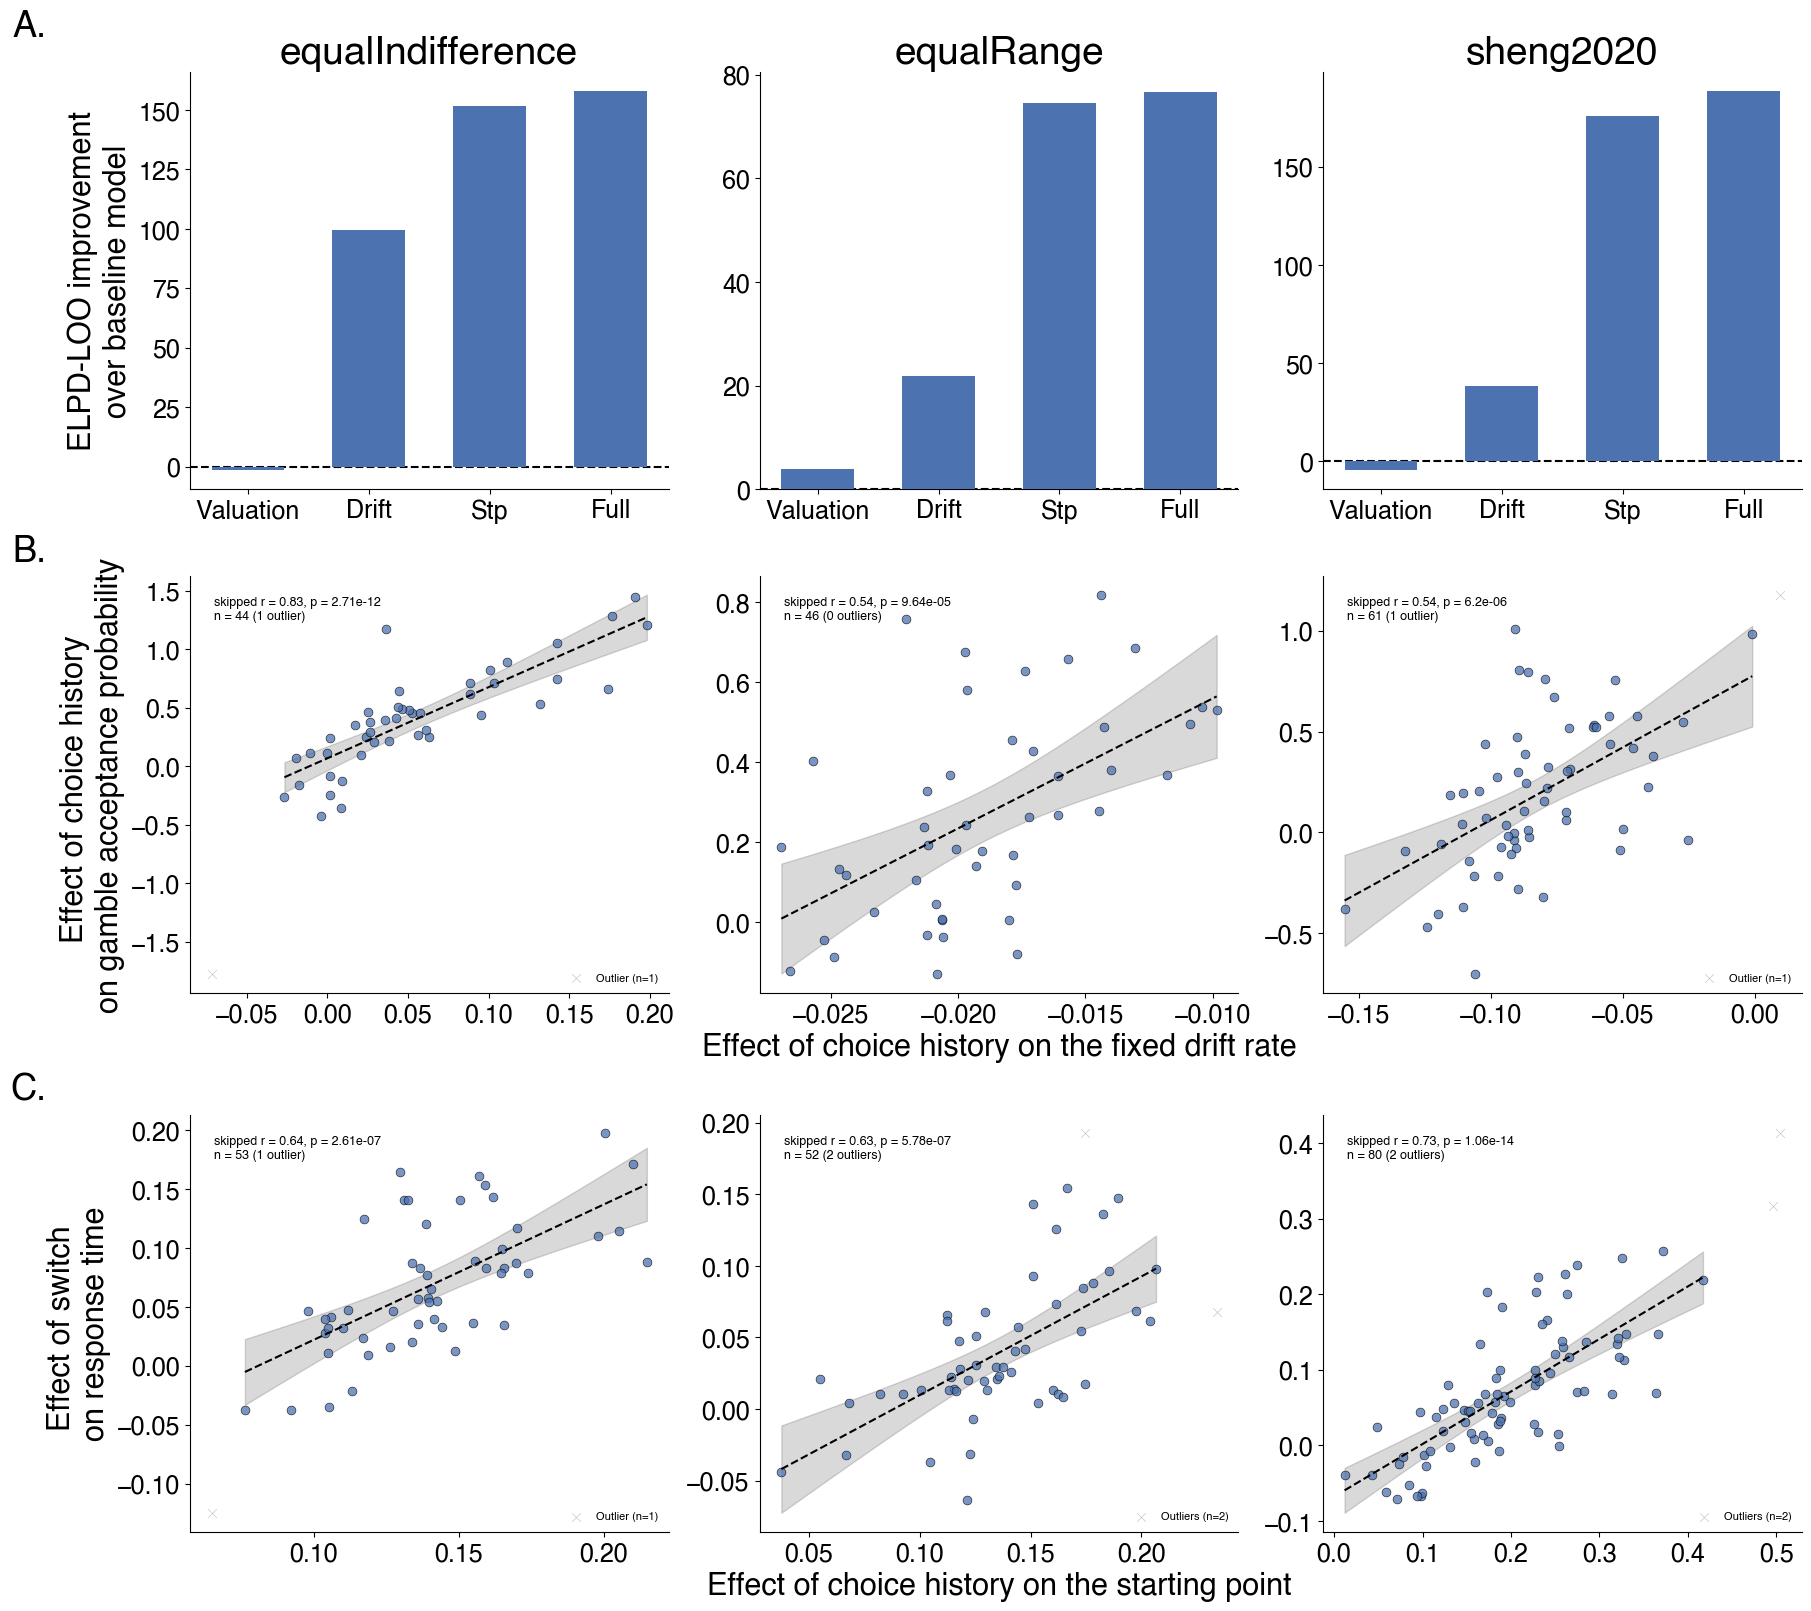

In [3]:
BASELINE_MODEL = "HDDM_Base"

ELPD_MODEL_ORDER = [
    ("HDDM_Base_Lag1-stim",  "Valuation"),
    ("HDDM_Base_Lag1-drift", "Drift"),
    ("HDDM_Base_Lag1-stp",   "Stp"),
    ("HDDM_Base_Lag1-full",  "Full"),
]

elpd_vs_baseline = {}
for ds in DATASETS:
    loo = load_loo_comparison(ds).set_index("model")["elpd_loo"]
    baseline_elpd = loo[BASELINE_MODEL]
    elpd_vs_baseline[ds] = [loo[m] - baseline_elpd for m, _ in ELPD_MODEL_ORDER]

choicehistory_betas = load_choicehistorypersubject_betas()
choicehistory_betas = choicehistory_betas[choicehistory_betas["converged"]]

switch_betas = load_rtlme_switchpersubject_betas()
switch_betas = switch_betas[switch_betas["converged"]]

drift_vs_choice = {}
z_vs_switch = {}
for ds in DATASETS:
    full_params = load_ddm_subj_params(FULL_DDM_MODEL, ds)

    beh_ds = (choicehistory_betas[choicehistory_betas["dataset"] == ds]
              .set_index("sub")["choice_prev1_effect"])
    v_cp1 = (full_params[full_params["param_name"] == "v_choice_prev1"]
             .set_index("sub")["param_value"])
    v_cp1.name = "v_choice_prev1"
    drift_vs_choice[ds] = pd.concat(
        [v_cp1, beh_ds.rename("choice_prev1_effect")], axis=1, join="inner"
    )

    switch_ds = (switch_betas[switch_betas["dataset"] == ds]
                 .set_index("sub")["switch_effect"])
    z_cp1 = (full_params[full_params["param_name"] == "z_choice_prev1"]
             .set_index("sub")["param_value"])
    z_cp1.name = "z_choice_prev1"
    z_vs_switch[ds] = pd.concat(
        [z_cp1, switch_ds.rename("switch_effect")], axis=1, join="inner"
    )

fig, axes = plt.subplots(nrows=3, ncols=3, figsize=(18, 16), layout="constrained")

x_pos = np.arange(len(ELPD_MODEL_ORDER))
x_labels = [label for _, label in ELPD_MODEL_ORDER]

# --- Row A: LOO improvement over baseline ---
for col, ds in enumerate(DATASETS):
    ax = axes[0, col]
    diffs = elpd_vs_baseline[ds]

    ax.bar(x_pos, diffs, color=RT_CORR_COLOR, width=0.6, zorder=3)
    ax.axhline(0, color="black", linestyle="--", linewidth=1.5, zorder=2)

    ax.set_xticks(x_pos)
    ax.set_xticklabels(x_labels)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.set_title(DATASET_LABELS.get(ds, ds))
    if col == 0:
        ax.set_ylabel("ELPD-LOO improvement\nover baseline model")

# --- Row B: behavioral choice-history effect vs. DDM drift bias ---
for col, ds in enumerate(DATASETS):
    ax = axes[1, col]
    merged = drift_vs_choice[ds]
    plot_robust_corr(ax, merged["v_choice_prev1"].values,
                      merged["choice_prev1_effect"].values, RT_CORR_COLOR)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    if col == 0:
        ax.set_ylabel("Effect of choice history \non gamble acceptance probability")
    if col == 1:
        ax.set_xlabel("Effect of choice history on the fixed drift rate")

# --- Row C: RT switch effect vs. DDM starting-point bias ---
for col, ds in enumerate(DATASETS):
    ax = axes[2, col]
    merged = z_vs_switch[ds]
    plot_robust_corr(ax, merged["z_choice_prev1"].values,
                      merged["switch_effect"].values, RT_CORR_COLOR)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    if col == 0:
        ax.set_ylabel("Effect of switch \non response time")
    if col == 1:
        ax.set_xlabel("Effect of choice history on the starting point")

# Row labels, placed just outside the top-left corner of each row's leftmost
# panel (same convention as figure1.ipynb's "A."/"B."/"C.")
axes[0, 0].text(-0.3, 1.15, "A.", transform=axes[0, 0].transAxes,
               fontsize=26, fontweight="bold", va="top", ha="right")
axes[1, 0].text(-0.3, 1.1, "B.", transform=axes[1, 0].transAxes,
               fontsize=26, fontweight="bold", va="top", ha="right")
axes[2, 0].text(-0.3, 1.1, "C.", transform=axes[2, 0].transAxes,
               fontsize=26, fontweight="bold", va="top", ha="right")

fig.savefig("saved/figure3_v2.svg", dpi=300, bbox_inches="tight")

plt.show()

### Heatmap: choice-history DDM parameters vs. behavioral effects
For each dataset, per-subject robust (skipped) correlations between four DDM
parameters that capture the choice-history effect -- `z_choice_prev1`
(starting point), `v_choice_prev1` (drift), `v_gain_centered:choice_prev1`
(gain-sensitivity modulation), and the per-subject valuation-bias
difference `(v_loss_centered + v_loss_centered:choice_prev1) /
(v_gain_centered + v_gain_centered:choice_prev1) - (v_loss_centered -
v_loss_centered:choice_prev1) / (v_gain_centered -
v_gain_centered:choice_prev1)` (the per-subject analog of `lambda_accept -
lambda_reject` from the group-level posterior figure in `figure3.ipynb`) --
against the two behavioral effects already used above: `choice_prev1_effect`
(choice history's effect on gamble-acceptance probability) and
`switch_effect` (choice history's effect on RT). One heatmap per dataset;
cell color is `-log10(p)` (capped at 5, i.e. p = 1e-5, since resolution
beyond that isn't meaningful -- one shared colorbar/color scale across all
three panels so datasets are directly comparable), and the robust
correlation coefficient `r` is printed inside each cell. Reuses
`robust_corr_line` from the cell above.

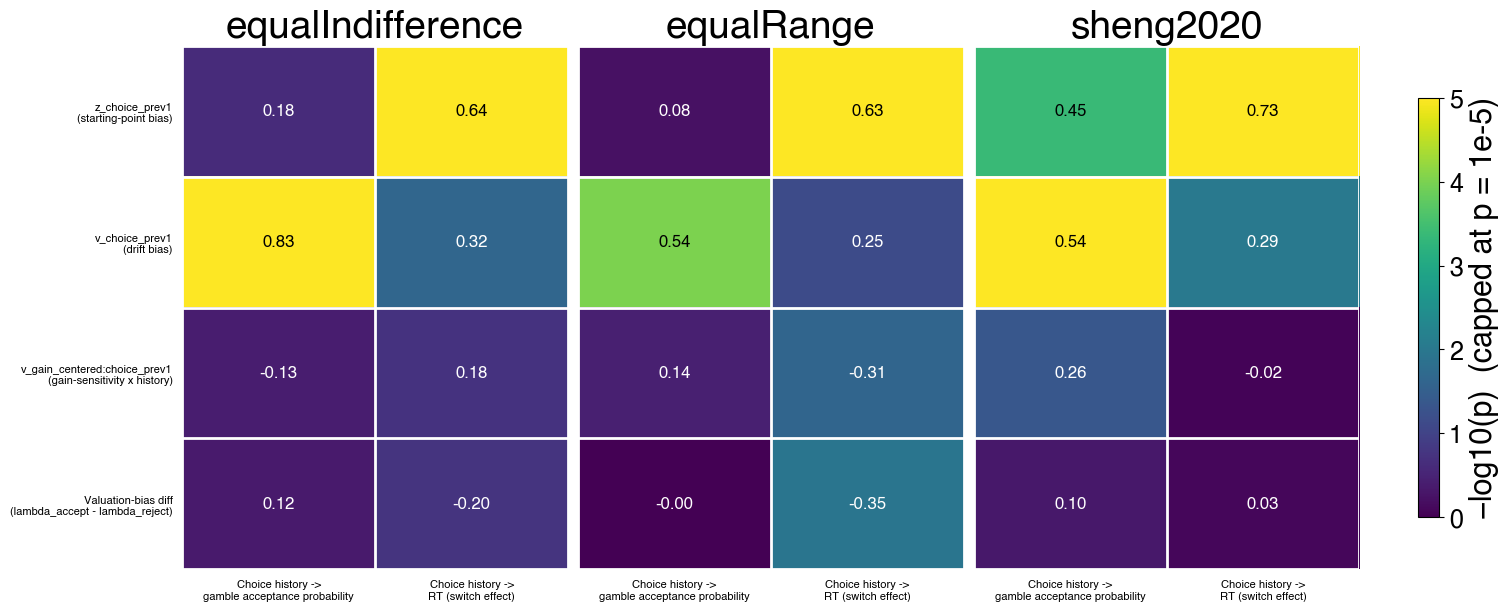

In [4]:
DDM_PARAM_SPECS = [
    ("z_choice_prev1", "z_choice_prev1\n(starting-point bias)"),
    ("v_choice_prev1", "v_choice_prev1\n(drift bias)"),
    ("v_gain_centered:choice_prev1", "v_gain_centered:choice_prev1\n(gain-sensitivity x history)"),
]

BEHAVIOR_SPECS = [
    ("choice_prev1_effect", "Choice history ->\ngamble acceptance probability"),
    ("switch_effect", "Choice history ->\nRT (switch effect)"),
]

NEG_LOG10_P_CAP = 5  # p = 1e-5; finer resolution beyond this isn't meaningful

heatmap_data = {}
for ds in DATASETS:
    full_params = (load_ddm_subj_params(FULL_DDM_MODEL, ds)
                   .pivot(index="sub", columns="param_name", values="param_value"))

    # Per-subject analog of the group-level lambda_accept - lambda_reject
    # (Valuation Bias) used in the posterior-samples figure.
    lambda_accept = ((full_params["v_loss_centered"] + full_params["v_loss_centered:choice_prev1"]) /
                      (full_params["v_gain_centered"] + full_params["v_gain_centered:choice_prev1"]))
    lambda_reject = ((full_params["v_loss_centered"] - full_params["v_loss_centered:choice_prev1"]) /
                      (full_params["v_gain_centered"] - full_params["v_gain_centered:choice_prev1"]))
    full_params["valuation_bias_diff"] = lambda_accept - lambda_reject

    ddm_specs = DDM_PARAM_SPECS + [
        ("valuation_bias_diff", "Valuation-bias diff\n(lambda_accept - lambda_reject)"),
    ]

    behavior_values = {
        "choice_prev1_effect": (choicehistory_betas[choicehistory_betas["dataset"] == ds]
                                 .set_index("sub")["choice_prev1_effect"]),
        "switch_effect": (switch_betas[switch_betas["dataset"] == ds]
                           .set_index("sub")["switch_effect"]),
    }

    r_mat = np.full((len(ddm_specs), len(BEHAVIOR_SPECS)), np.nan)
    p_mat = np.full((len(ddm_specs), len(BEHAVIOR_SPECS)), np.nan)

    for i, (ddm_col, _) in enumerate(ddm_specs):
        for j, (beh_col, _) in enumerate(BEHAVIOR_SPECS):
            merged = pd.concat(
                [full_params[ddm_col].rename("ddm"), behavior_values[beh_col].rename("beh")],
                axis=1, join="inner",
            ).dropna()
            result = robust_corr_line(merged["ddm"].values, merged["beh"].values)
            r_mat[i, j] = result["r"]
            p_mat[i, j] = result["pval"]

    heatmap_data[ds] = {
        "r": r_mat,
        "neg_log10_p": np.clip(-np.log10(p_mat), 0, NEG_LOG10_P_CAP),
        "ddm_labels": [lbl for _, lbl in ddm_specs],
    }

fig_heat, axes_heat = plt.subplots(nrows=1, ncols=3, figsize=(15, 6), layout="constrained")

cmap = plt.get_cmap("viridis")
norm = mpl.colors.Normalize(vmin=0, vmax=NEG_LOG10_P_CAP)
beh_labels = [lbl for _, lbl in BEHAVIOR_SPECS]

for col, ds in enumerate(DATASETS):
    ax = axes_heat[col]
    r_mat = heatmap_data[ds]["r"]
    color_vals = heatmap_data[ds]["neg_log10_p"]
    ddm_labels = heatmap_data[ds]["ddm_labels"]

    ax.imshow(color_vals, cmap=cmap, norm=norm, aspect="auto")

    for i in range(r_mat.shape[0]):
        for j in range(r_mat.shape[1]):
            cell_rgba = cmap(norm(color_vals[i, j]))
            luminance = 0.299 * cell_rgba[0] + 0.587 * cell_rgba[1] + 0.114 * cell_rgba[2]
            text_color = "white" if luminance < 0.5 else "black"
            ax.text(j, i, f"{r_mat[i, j]:.2f}", ha="center", va="center",
                    color=text_color, fontsize=12, fontweight="bold")

    ax.set_xticks(range(len(beh_labels)))
    ax.set_xticklabels(beh_labels, fontsize=8)
    ax.set_yticks(range(len(ddm_labels)))
    ax.set_yticklabels(ddm_labels if col == 0 else [], fontsize=8)
    ax.set_title(DATASET_LABELS.get(ds, ds))

    ax.set_xticks(np.arange(-0.5, len(beh_labels), 1), minor=True)
    ax.set_yticks(np.arange(-0.5, len(ddm_labels), 1), minor=True)
    ax.grid(which="minor", color="white", linewidth=2)
    ax.tick_params(which="both", bottom=False, left=False)
    for spine in ax.spines.values():
        spine.set_visible(False)

fig_heat.colorbar(mpl.cm.ScalarMappable(norm=norm, cmap=cmap), ax=axes_heat,
                   shrink=0.8, label="−log10(p)  (capped at p = 1e-5)")

fig_heat.savefig("saved/figure3_v2_heatmap.svg", dpi=300, bbox_inches="tight")

plt.show()